In [40]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest,f_classif

In [2]:
diabetes=pd.read_csv('Healthcare-Diabetes.csv')

In [3]:
diabetes.head()

,Id,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,1,6,148,72,35,0,33.6,0.627,50,1
1,2,1,85,66,29,0,26.6,0.351,31,0
2,3,8,183,64,0,0,23.3,0.672,32,1
3,4,1,89,66,23,94,28.1,0.167,21,0
4,5,0,137,40,35,168,43.1,2.288,33,1


In [4]:
diabetes.columns

Index(['Id', 'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
       'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='str')

In [5]:
diabetes.isnull().sum()

Id                          0
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [6]:
diabetes.info()

<class 'pandas.DataFrame'>
RangeIndex: 2768 entries, 0 to 2767
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Id                        2768 non-null   int64  
 1   Pregnancies               2768 non-null   int64  
 2   Glucose                   2768 non-null   int64  
 3   BloodPressure             2768 non-null   int64  
 4   SkinThickness             2768 non-null   int64  
 5   Insulin                   2768 non-null   int64  
 6   BMI                       2768 non-null   float64
 7   DiabetesPedigreeFunction  2768 non-null   float64
 8   Age                       2768 non-null   int64  
 9   Outcome                   2768 non-null   int64  
dtypes: float64(2), int64(8)
memory usage: 216.4 KB


In [7]:
diabetes.describe()

,Id,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,2768.000000,2768.000000,2768.000000,2768.000000,2768.000000,2768.000000,2768.000000,2768.000000,2768.000000,2768.000000
mean,1384.500000,3.742775,121.102601,69.134393,20.824422,80.127890,32.137392,0.471193,33.132225,0.343931
std,799.197097,3.323801,32.036508,19.231438,16.059596,112.301933,8.076127,0.325669,11.777230,0.475104
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,692.750000,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.244000,24.000000,0.000000
50%,1384.500000,3.000000,117.000000,72.000000,23.000000,37.000000,32.200000,0.375000,29.000000,0.000000
75%,2076.250000,6.000000,141.000000,80.000000,32.000000,130.000000,36.625000,0.624000,40.000000,1.000000
max,2768.000000,17.000000,199.000000,122.000000,110.000000,846.000000,80.600000,2.420000,81.000000,1.000000


In [8]:
(diabetes[['Glucose', 'BloodPressure', 'SkinThickness',
       'Insulin', 'BMI']]==0).sum()

Glucose            18
BloodPressure     125
SkinThickness     800
Insulin          1330
BMI                39
dtype: int64

In [9]:
cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

# Step 1: Replace 0 with NaN and assign back
diabetes[cols] = diabetes[cols].replace(0, np.nan)

In [10]:
diabetes[cols].isna().sum()

Glucose            18
BloodPressure     125
SkinThickness     800
Insulin          1330
BMI                39
dtype: int64

In [11]:
diabetes=diabetes.fillna(diabetes.median(), inplace=True)

In [12]:
diabetes.isna().sum()

Id                          0
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [13]:
# Target distribution
print(diabetes['Outcome'].value_counts())
print(diabetes['Outcome'].value_counts(normalize=True) * 100)

Outcome
0    1816
1     952
Name: count, dtype: int64
Outcome
0    65.606936
1    34.393064
Name: proportion, dtype: float64


In [16]:
diabetes=diabetes.drop(columns=['Id'])

## data visualization

C:\Users\ROBIN\AppData\Local\Temp\ipykernel_6012\2860556457.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Outcome', y='Glucose', data=diabetes,palette='Set2')


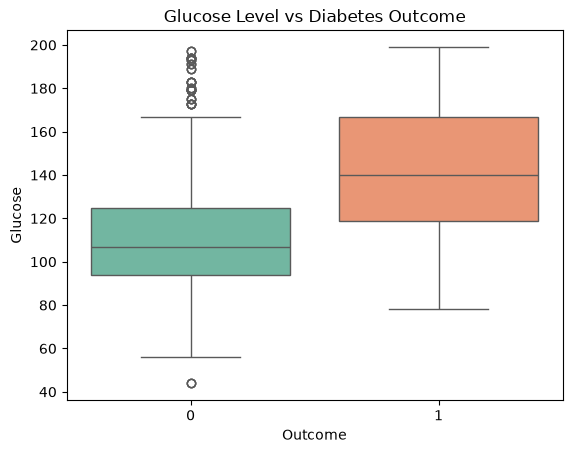

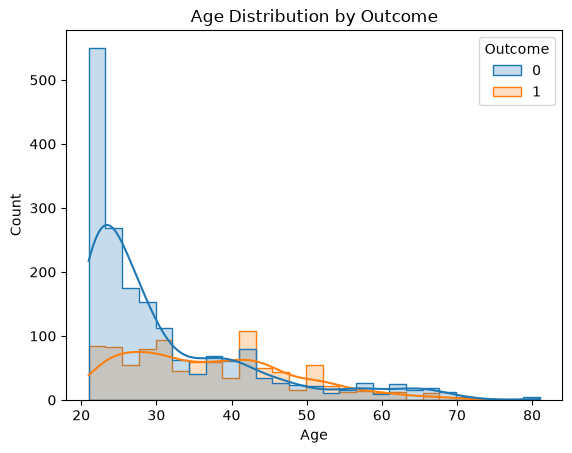

In [14]:
sns.boxplot(x='Outcome', y='Glucose', data=diabetes,palette='Set2')
plt.title("Glucose Level vs Diabetes Outcome")
plt.show()

# Age distribution for Diabetic vs Non-Diabetic
sns.histplot(data=diabetes, x='Age', hue='Outcome', kde=True, element="step")
plt.title("Age Distribution by Outcome")
plt.show()

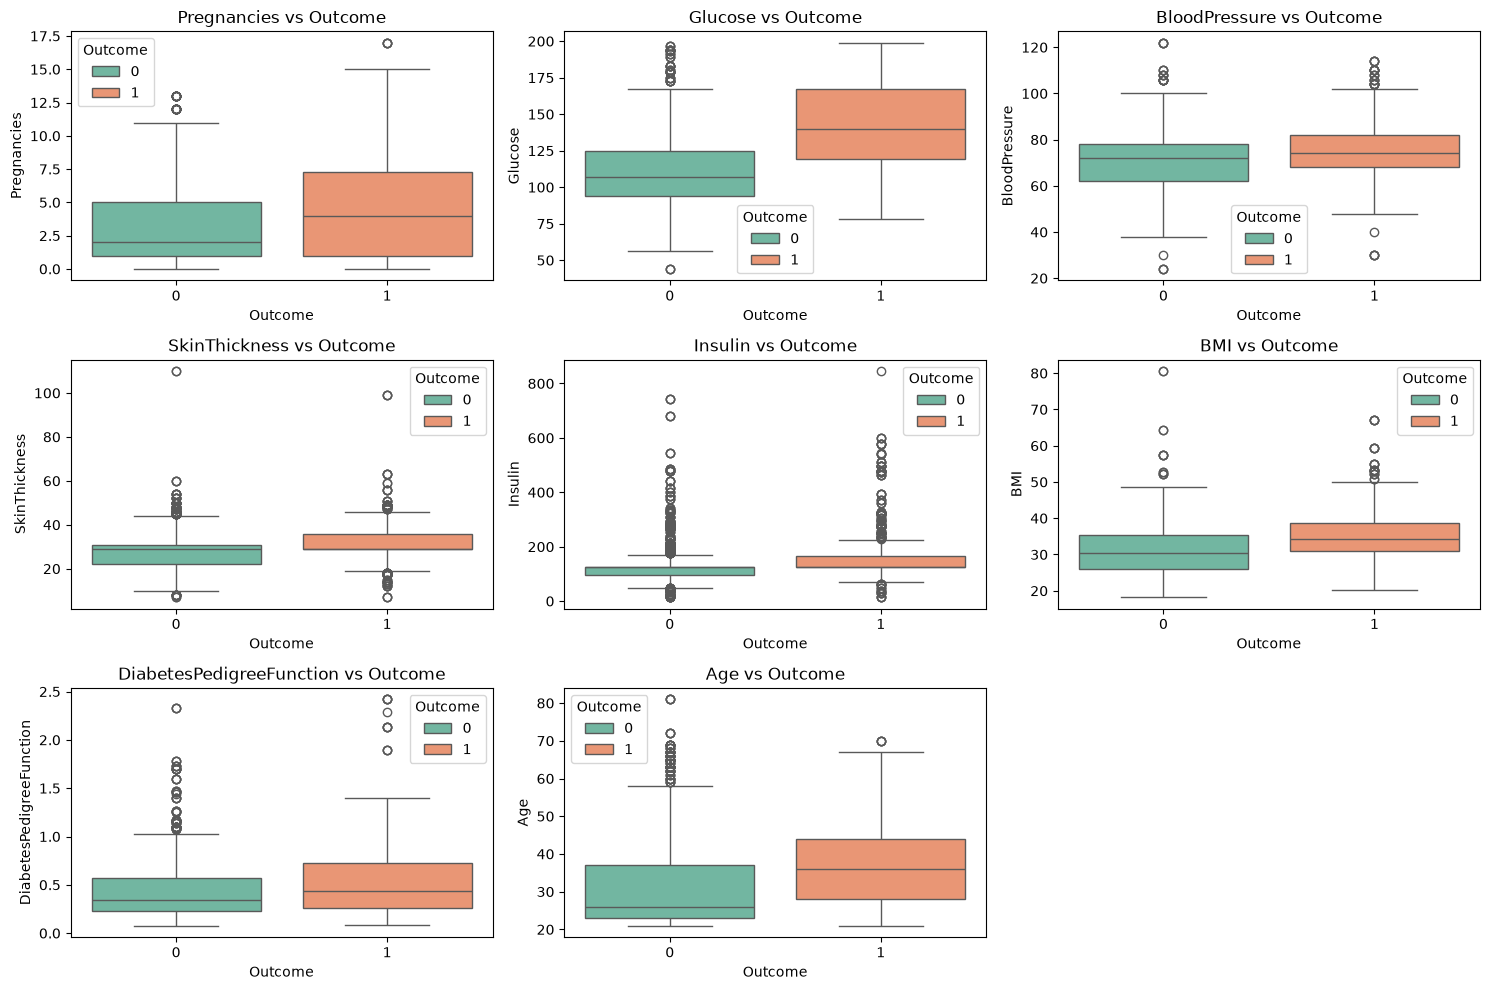

In [25]:
feature=['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
       'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
plt.figure(figsize=(15,10))

for i,col in enumerate(feature,1):
    plt.subplot(3,3,i)
    sns.boxplot(x='Outcome',y=col,data=diabetes,palette='Set2',hue='Outcome')
    plt.title(f'{col} vs Outcome')

plt.tight_layout()
plt.show()
    
    

In [48]:
exclude_col=['Insulin','DiabetesPedigreeFunction','SkinThickness','Outcome']

In [49]:
feture_col=[col for col in diabetes.columns if col not in exclude_col ]

In [50]:
feture_col

['Pregnancies', 'Glucose', 'BloodPressure', 'BMI', 'Age']

In [51]:
x=diabetes[feture_col]
y=diabetes['Outcome']

## scaling the data

In [54]:
scale=StandardScaler()
x_scaled=scale.fit_transform(x)
x_scaled

array([[ 0.67923239,  0.85699293, -0.03218971,  0.14166153,  1.43249494],
       [-0.82534128, -1.20871707, -0.53275772, -0.84395152, -0.18107914],
       [ 1.28106186,  2.0046096 , -0.69961372, -1.30859768, -0.09615419],
       ...,
       [ 0.67923239, -1.20871707,  0.4683783 , -0.19626295,  0.75309532],
       [-1.12625601,  0.23400103,  3.13807435,  4.858524  , -0.6057039 ],
       [-0.52442655, -1.33987326, -0.03218971, -0.351145  , -0.69062885]],
      shape=(2768, 5))

## split the data for model

In [55]:
x_train,x_test,y_train,y_test=train_test_split(x_scaled,y)

## create and train test the model

In [65]:
diabetes_model=KNeighborsClassifier(n_neighbors=3)

In [66]:
diabetes_model.fit(x_train,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [67]:
y_pred=diabetes_model.predict(x_test)

## evaluate the model

In [68]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score

# Test data predictions
y_pred = diabetes_model.predict(x_test)

# 1. Accuracy Score
print("Accuracy:", accuracy_score(y_test, y_pred))

# 2. Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# 3. Detailed Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9320809248554913

Confusion Matrix:
[[420  29]
 [ 18 225]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.94      0.95       449
           1       0.89      0.93      0.91       243

    accuracy                           0.93       692
   macro avg       0.92      0.93      0.93       692
weighted avg       0.93      0.93      0.93       692



## visualize the model

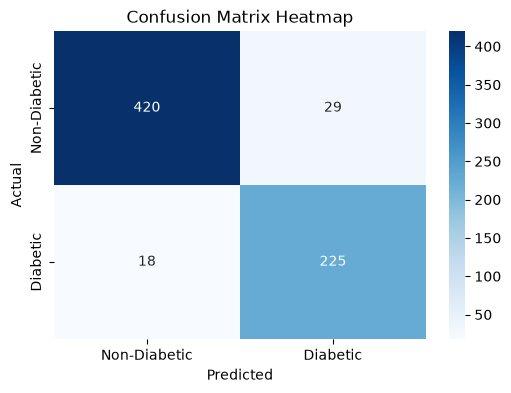

In [69]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Non-Diabetic', 'Diabetic'], 
            yticklabels=['Non-Diabetic', 'Diabetic'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix Heatmap')
plt.show()

## improve the model evaluation

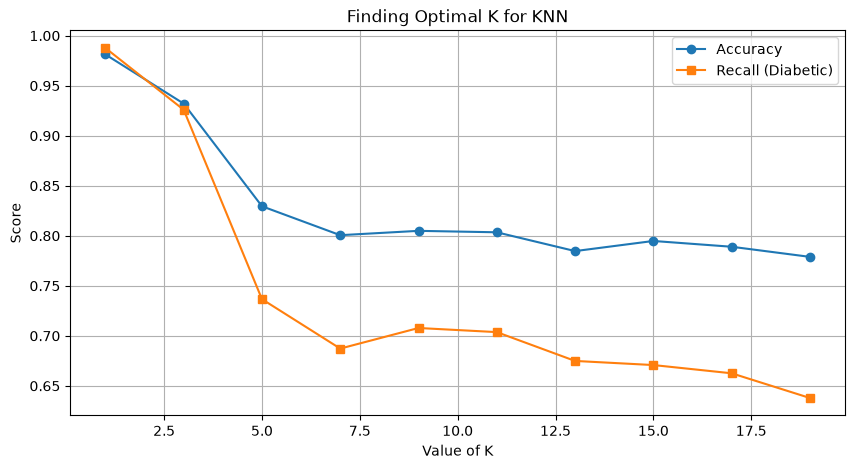

In [64]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, recall_score

acc_list = []
rec_list = []
k_values = range(1, 21, 2) # Odd numbers 1 to 19

for k in k_values:
    knn_model = KNeighborsClassifier(n_neighbors=k)
    knn_model.fit(x_train, y_train)
    y_pred_k = knn_model.predict(x_test)
    
    acc_list.append(accuracy_score(y_test, y_pred_k))
    rec_list.append(recall_score(y_test, y_pred_k))

# Line Chart visualization
plt.figure(figsize=(10, 5))
plt.plot(k_values, acc_list, label='Accuracy', marker='o')
plt.plot(k_values, rec_list, label='Recall (Diabetic)', marker='s')
plt.xlabel('Value of K')
plt.ylabel('Score')
plt.title('Finding Optimal K for KNN')
plt.legend()
plt.grid(True)
plt.show()